# Phase 3 — Mechanism Analysis and Cold Start

## Questions arising from Phase 2

| Finding | Question raised |
|---|---|
| gafgyt:tcp and gafgyt:udp are not detected in any configuration | **Is the threshold too high, or do they really look normal?** |
| Danmini: D-D 100%, C-D 0.12% | Why does pooling destroy the capability? |
| The personalization premium rests on a single device | Is this device a special case, or an instance of the general pattern? |

## Structure of this notebook

**Part A — Diagnosis (no training required).** Using the reconstruction errors in the Phase 2
checkpoint, we determine why the hard attacks are invisible.

**Part B — Mechanism.** Feature-level inspection: on which features is Danmini's
normal range narrow while the pooled model's is wide?

**Part C — Cold start (RQ2).** A learning curve is produced by gradually enlarging the
calibration window.

---

### Why Part A matters

There can be two entirely different reasons an attack is not caught:

1. **Threshold problem** — the model gives the attack a high anomaly score but the threshold is even higher.
   In this case ROC-AUC comes out high. The fix is threshold tuning, which is easy.
2. **Invisibility** — the model gives the attack the same score as normal traffic. ROC-AUC comes out around 0.5.
   There is no fix; the features do not carry this attack.

The two lead to completely different conclusions. In Phase 2 we looked only at the detection rate at a fixed
threshold and could not make this distinction.

## 0. Environment and data

In [1]:
import sys, os, glob, time, json, pickle, random, warnings
from collections import defaultdict

_PYLIBS = os.path.expanduser("~/work/pylibs")
if os.path.isdir(_PYLIBS) and _PYLIBS not in sys.path:
    sys.path.insert(0, _PYLIBS)

os.environ["OMP_NUM_THREADS"]      = "8"
os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["MKL_NUM_THREADS"]      = "8"
os.environ["CUDA_CACHE_PATH"]      = os.path.expanduser("~/work/.cuda_cache")
os.makedirs(os.environ["CUDA_CACHE_PATH"], exist_ok=True)

import ctypes
try:
    import nvidia
    libdirs = sorted(glob.glob(os.path.join(os.path.dirname(nvidia.__file__), "*", "lib")))
    os.environ["LD_LIBRARY_PATH"] = ":".join(libdirs) + ":" + os.environ.get("LD_LIBRARY_PATH", "")
    n = 0
    for d in libdirs:
        for so in sorted(glob.glob(os.path.join(d, "*.so*"))):
            try: ctypes.CDLL(so, mode=ctypes.RTLD_GLOBAL); n += 1
            except OSError: pass
    print(f"{n} CUDA libraries preloaded")
except ImportError:
    print("no nvidia packages - CPU")

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt; import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
matplotlib.rcParams["figure.dpi"] = 60
matplotlib.rcParams["savefig.dpi"] = 300
matplotlib.rcParams["savefig.bbox"] = "tight"
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

31 CUDA kutuphanesi on-yuklendi


I0000 00:00:1790678626.510994  234339 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790678626.536478  234339 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790678627.011362  234339 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1790678627.317730  234339 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binar

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ============ SETTINGS ====================================================
KOK  = os.path.expanduser("~/work/IoT_Botnet/veri/nbaiot")
F2   = os.path.expanduser("~/work/IoT_Botnet/faz2_ciktilar")
OUT  = os.path.expanduser("~/work/IoT_Botnet/faz3_ciktilar")
for s in ("figures", "tables"): os.makedirs(f"{OUT}/{s}", exist_ok=True)
CKPT = f"{OUT}/faz3_checkpoint.pkl"

SEED, SEED2 = 42, 7
EPOCHS, BATCH, PATIENCE, LR, KOD_BOYUT = 60, 256, 8, 1e-3, 16
KALIBRASYON, ESIK_DILIM = 0.60, 0.10
HEDEF_FPR = 0.01
SALDIRI_TEST = 30_000

# Hard subset - types that no configuration could detect in Phase 2
ZOR_TURLER = ["gafgyt:tcp", "gafgyt:udp"]

# Cold-start window sizes (number of calibration rows)
PENCERELER = [250, 500, 1000, 2500, 5000, 10000, 25000, None]  # None = all

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
    os.environ["PYTHONHASHSEED"] = str(s)

def savefig(ad):
    plt.savefig(f"{OUT}/figures/{ad}.png"); plt.show()

print("Output:", OUT)

Cikti: /home/jovyan/work/IoT_Botnet/faz3_ciktilar


In [3]:
# ---- Phase 2 checkpoint (errors are here, no retraining needed) ---------
with open(f"{F2}/faz2_checkpoint.pkl", "rb") as f:
    F2DURUM = pickle.load(f)
print(f"Phase 2 record: {len(F2DURUM['sonuclar'])} evaluations, "
      f"{len(F2DURUM['hatalar'])} error sets")

# ---- Raw data (for Parts B and C) --------------------------------------
def dosya_bilgisi(yol):
    p = os.path.relpath(yol, KOK).split(os.sep)
    if len(p) == 2: return p[0], "benign", "benign"
    return p[0], p[1].replace("_attacks", ""), os.path.splitext(p[-1])[0]

dosyalar = [f for f in sorted(glob.glob(f"{KOK}/**/*.csv", recursive=True))
            if "demonstrate" not in f]
t0 = time.time()
IYI, SALDIRI = {}, defaultdict(dict)
for f in dosyalar:
    cihaz, aile, tur = dosya_bilgisi(f)
    df = pd.read_csv(f, dtype="float32")
    if aile == "benign":
        IYI[cihaz] = df.to_numpy()
    else:
        A = df.to_numpy()
        SALDIRI[cihaz][f"{aile}:{tur}"] = A[:SALDIRI_TEST]

OZNITELIKLER = list(pd.read_csv(dosyalar[0], nrows=1).columns)
CIHAZLAR = sorted(IYI)

def bol(A):
    n = len(A); i1 = int(KALIBRASYON*n); i2 = int((KALIBRASYON+ESIK_DILIM)*n)
    return A[:i1], A[i1:i2], A[i2:]

BOLUM = {c: dict(zip(("kalibrasyon","esik","test"), bol(IYI[c]))) for c in CIHAZLAR}
print(f"Data loaded ({time.time()-t0:.0f} s) | {len(CIHAZLAR)} devices, "
      f"{len(OZNITELIKLER)} features")

Faz 2 kaydi: 54 degerlendirme, 54 hata kumesi
Veri yuklendi (28 s) | 9 cihaz, 115 oznitelik


# Part A — Diagnosis of the hard attacks

The reconstruction errors saved in Phase 2 are used. No model is
trained.

For each device and each attack type, we compute ROC-AUC by comparing **only that type** against the benign test data.

- **AUC $\approx$ 0.5** → the attack gets the same score as normal traffic. Invisible.
- **High AUC but low TPR** → the scores separate but the threshold is in the wrong place.

In [4]:
satirlar = []
for (yad, cihaz), h in F2DURUM["hatalar"].items():
    iyi = h["iyi"]; esik = h["esik"]
    for tur, sh in h["saldiri"].items():
        y = np.r_[np.zeros(len(iyi)), np.ones(len(sh))]
        s = np.r_[iyi, sh]
        satirlar.append({
            "yapilandirma": yad, "cihaz": cihaz, "tur": tur,
            "aile": tur.split(":")[0],
            "TPR@esik": float((sh > esik).mean()),
            "ROC_AUC": float(roc_auc_score(y, s)),
            "PR_AUC": float(average_precision_score(y, s)),
            "medyan_oran": float(np.median(sh) / (np.median(iyi) + 1e-12)),
        })
tani = pd.DataFrame(satirlar)
tani.to_csv(f"{OUT}/tables/f3_tablo1_tur_bazli_tani.csv", index=False)

ozet = (tani[tani.yapilandirma.isin(["D-D", "G-G"])]
        .groupby(["yapilandirma", "tur"])[["TPR@esik", "ROC_AUC", "PR_AUC"]]
        .mean().round(4).unstack(0))
print(ozet.to_string())

               TPR@esik         ROC_AUC          PR_AUC        
yapilandirma        D-D     G-G     D-D     G-G     D-D     G-G
tur                                                            
gafgyt:combo     0.9999  0.9997  1.0000  1.0000  1.0000  1.0000
gafgyt:junk      0.9999  0.9996  1.0000  1.0000  1.0000  1.0000
gafgyt:scan      0.9998  0.9996  0.9999  1.0000  0.9999  1.0000
gafgyt:tcp       0.1119  0.0004  0.9714  0.9033  0.9836  0.9504
gafgyt:udp       0.1115  0.0000  0.9714  0.9033  0.9839  0.9506
mirai:ack        0.9999  0.9999  1.0000  1.0000  1.0000  1.0000
mirai:scan       0.9994  0.9990  1.0000  0.9999  0.9999  1.0000
mirai:syn        0.9999  0.9996  1.0000  1.0000  0.9999  1.0000
mirai:udp        0.9998  0.9997  1.0000  1.0000  1.0000  1.0000
mirai:udpplain   1.0000  0.9999  1.0000  1.0000  1.0000  1.0000


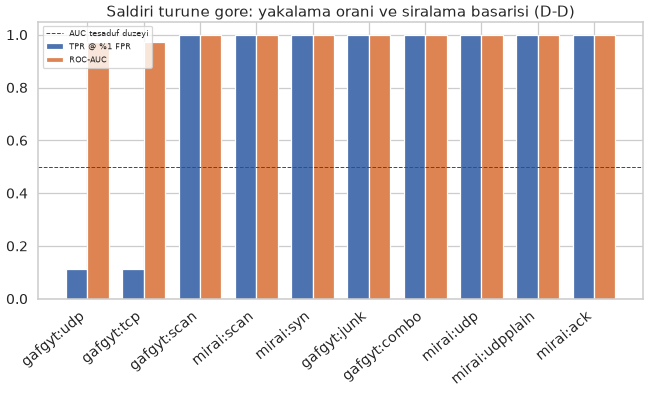

TANI:
  gafgyt:udp         TPR=0.1115  AUC=0.9714  -> ESIK SORUNU - skorlar ayrisiyor ama esik yanlis yerde
  gafgyt:tcp         TPR=0.1119  AUC=0.9714  -> ESIK SORUNU - skorlar ayrisiyor ama esik yanlis yerde
  gafgyt:scan        TPR=0.9998  AUC=0.9999  -> sorunsuz
  mirai:scan         TPR=0.9994  AUC=1.0000  -> sorunsuz
  mirai:syn          TPR=0.9999  AUC=1.0000  -> sorunsuz
  gafgyt:junk        TPR=0.9999  AUC=1.0000  -> sorunsuz
  gafgyt:combo       TPR=0.9999  AUC=1.0000  -> sorunsuz
  mirai:udp          TPR=0.9998  AUC=1.0000  -> sorunsuz
  mirai:udpplain     TPR=1.0000  AUC=1.0000  -> sorunsuz
  mirai:ack          TPR=0.9999  AUC=1.0000  -> sorunsuz


In [5]:
# ---- Figure: TPR and AUC side by side ----------------------------------------
dd = tani[tani.yapilandirma == "D-D"].groupby("tur")[["TPR@esik","ROC_AUC"]].mean()
dd = dd.sort_values("ROC_AUC")

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(dd)); w = 0.38
ax.bar(x - w/2, dd["TPR@esik"], w, label="TPR @ %1 FPR", color="#4c72b0")
ax.bar(x + w/2, dd["ROC_AUC"],  w, label="ROC-AUC",      color="#dd8452")
ax.axhline(0.5, color="red", ls="--", lw=1.2, label="AUC tesaduf duzeyi")
ax.set_xticks(x); ax.set_xticklabels(dd.index, rotation=40, ha="right")
ax.set_ylim(0, 1.05); ax.legend(fontsize=10)
ax.set_title("Saldiri turune gore: yakalama orani ve siralama basarisi (D-D)")
savefig("f3_fig01_tani")

print("DIAGNOSIS:")
for tur, r in dd.iterrows():
    if r.ROC_AUC < 0.6:
        durum = "GORUNMEZ - saldiri normal trafikle ayni skoru aliyor"
    elif r["TPR@esik"] < 0.5 and r.ROC_AUC > 0.8:
        durum = "ESIK SORUNU - skorlar ayrisiyor ama esik yanlis yerde"
    elif r["TPR@esik"] > 0.9:
        durum = "sorunsuz"
    else:
        durum = "kismi"
    print(f"  {tur:<18} TPR={r['TPR@esik']:.4f}  AUC={r.ROC_AUC:.4f}  -> {durum}")

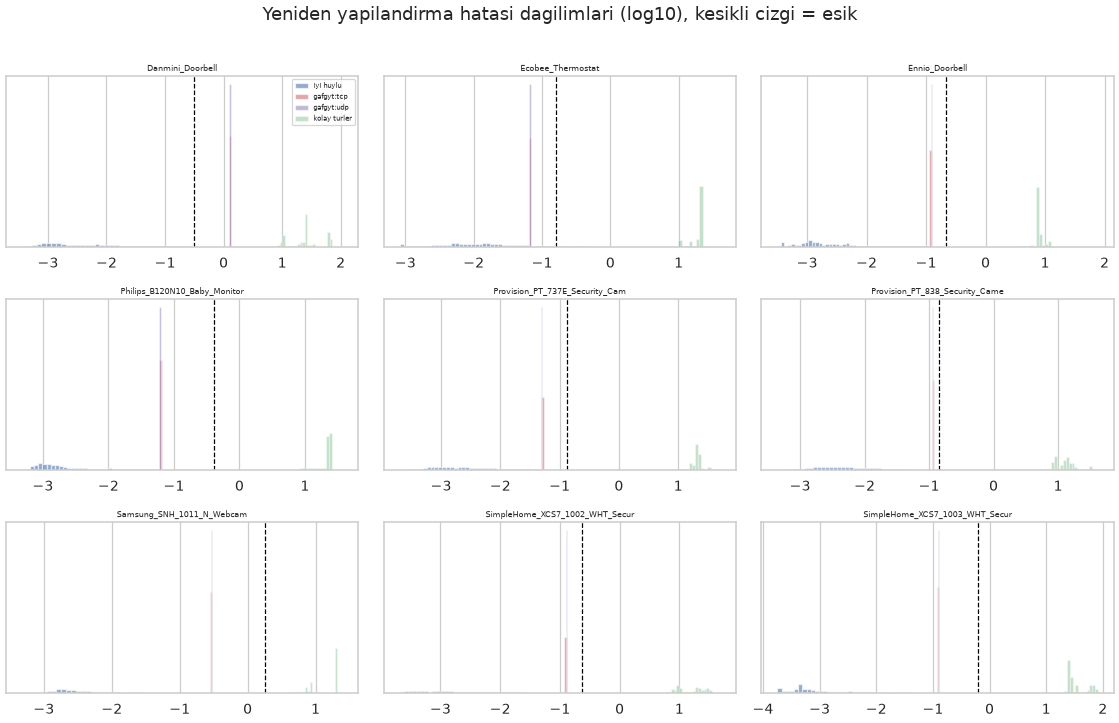

In [6]:
# ---- Comparison of error distributions on hard types -------------------
hedef = [c for c in CIHAZLAR]
fig, axes = plt.subplots(3, 3, figsize=(19, 12), sharex=False)
for ax, cihaz in zip(axes.ravel(), hedef):
    h = F2DURUM["hatalar"].get(("D-D", cihaz))
    if h is None: continue
    iyi = np.log10(h["iyi"] + 1e-12)
    ax.hist(iyi, bins=60, alpha=0.6, label="iyi huylu", color="#4c72b0", density=True)
    for tur, renk in zip(ZOR_TURLER, ["#c44e52", "#8172b2"]):
        if tur in h["saldiri"]:
            ax.hist(np.log10(h["saldiri"][tur] + 1e-12), bins=60, alpha=0.5,
                    label=tur, color=renk, density=True)
    kolay = [t for t in h["saldiri"] if t not in ZOR_TURLER]
    if kolay:
        ax.hist(np.log10(np.concatenate([h["saldiri"][t] for t in kolay]) + 1e-12),
                bins=60, alpha=0.35, label="kolay turler", color="#55a868", density=True)
    ax.axvline(np.log10(h["esik"] + 1e-12), color="black", ls="--", lw=1.5)
    ax.set_title(cihaz[:30], fontsize=10)
    ax.set_yticks([])
axes[0][0].legend(fontsize=8)
plt.suptitle("Yeniden yapilandirma hatasi dagilimlari (log10), kesikli cizgi = esik", y=1.01)
plt.tight_layout(); savefig("f3_fig02_hata_dagilimlari")

# Part B — Mechanism: width of the normal region

Hypothesis: because Danmini's own normal range is narrow, gafgyt:tcp falls outside this range.
When pooled with other devices, the definition of "normal" widens and the attack falls
inside it.

This can be measured directly without training: for each feature we look at the spread of the
benign data.

Havuzlama, cihazin normal bolgesini kac kat genisletiyor?
(medyan oran, tum oznitelikler uzerinden)

                                   cihaz  ortalama_genisleme
SimpleHome_XCS7_1003_WHT_Security_Camera           30.252477
                        Danmini_Doorbell           10.455674
                          Ennio_Doorbell            2.910000
            Philips_B120N10_Baby_Monitor            2.852871
SimpleHome_XCS7_1002_WHT_Security_Camera            1.317553
       Provision_PT_737E_Security_Camera            1.003868
        Provision_PT_838_Security_Camera            0.403798
               Samsung_SNH_1011_N_Webcam            0.369255
                       Ecobee_Thermostat            0.162203


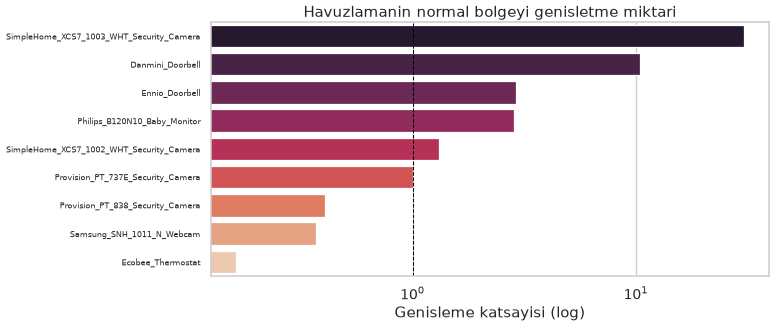

In [7]:
# ---- Width of the normal region (no training needed) ---------------------
def yayilim(A):
    """Robust spread measure (IQR) for each feature."""
    q1, q3 = np.percentile(A, [25, 75], axis=0)
    return q3 - q1

tek = {c: yayilim(BOLUM[c]["kalibrasyon"]) for c in CIHAZLAR}
havuz = yayilim(np.concatenate([BOLUM[c]["kalibrasyon"] for c in CIHAZLAR]))

gen = pd.DataFrame({
    "cihaz": CIHAZLAR,
    "ortalama_genisleme": [float(np.median(havuz / (tek[c] + 1e-9))) for c in CIHAZLAR],
})
gen = gen.sort_values("ortalama_genisleme", ascending=False)
gen.to_csv(f"{OUT}/tables/f3_tablo2_normal_genisleme.csv", index=False)
print("By how many times does pooling widen a device's normal region?")
print("(median ratio, across all features)\n")
print(gen.to_string(index=False))

plt.figure(figsize=(12, 5.5))
sns.barplot(data=gen, y="cihaz", x="ortalama_genisleme",
            hue="cihaz", palette="rocket", legend=False)
plt.axvline(1.0, color="black", ls="--", lw=1.2)
plt.xscale("log"); plt.xlabel("Genisleme katsayisi (log)")
plt.ylabel(""); plt.yticks(fontsize=9)
plt.title("Havuzlamanin normal bolgeyi genisletme miktari")
savefig("f3_fig03_normal_genisleme")

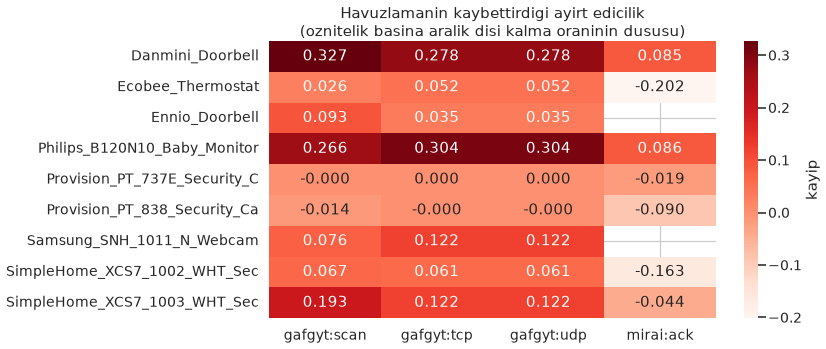

Zor turlerde en cok kayip yasayan cihazlar:
                                   cihaz        tur  disarida_tek_cihaz  disarida_havuz  kayip
            Philips_B120N10_Baby_Monitor gafgyt:udp              0.3479          0.0436 0.3043
            Philips_B120N10_Baby_Monitor gafgyt:tcp              0.3480          0.0437 0.3042
                        Danmini_Doorbell gafgyt:tcp              0.3220          0.0438 0.2782
                        Danmini_Doorbell gafgyt:udp              0.3218          0.0436 0.2782
SimpleHome_XCS7_1003_WHT_Security_Camera gafgyt:tcp              0.1656          0.0437 0.1219
SimpleHome_XCS7_1003_WHT_Security_Camera gafgyt:udp              0.1655          0.0436 0.1219


In [8]:
# ---- Where is the attack relative to the device's own range? ----------------------
# For each feature: are attack values outside the device's benign range?
def disarida_oran(iyi, saldiri, k=1.5):
    q1, q3 = np.percentile(iyi, [25, 75], axis=0)
    iqr = q3 - q1
    alt, ust = q1 - k*iqr, q3 + k*iqr
    return ((saldiri < alt) | (saldiri > ust)).mean(axis=0)

satir = []
havuz_iyi = np.concatenate([BOLUM[c]["kalibrasyon"] for c in CIHAZLAR])
for cihaz in CIHAZLAR:
    iyi = BOLUM[cihaz]["kalibrasyon"]
    for tur in ZOR_TURLER + ["gafgyt:scan", "mirai:ack"]:
        if tur not in SALDIRI[cihaz]: continue
        S = SALDIRI[cihaz][tur]
        d_tek = disarida_oran(iyi, S).mean()
        d_havuz = disarida_oran(havuz_iyi, S).mean()
        satir.append({"cihaz": cihaz, "tur": tur,
                      "disarida_tek_cihaz": round(float(d_tek), 4),
                      "disarida_havuz": round(float(d_havuz), 4),
                      "kayip": round(float(d_tek - d_havuz), 4)})
dis = pd.DataFrame(satir)
dis.to_csv(f"{OUT}/tables/f3_tablo3_aralik_disi.csv", index=False)

pv = dis.pivot(index="cihaz", columns="tur", values="kayip")
plt.figure(figsize=(12, 6))
sns.heatmap(pv, annot=True, fmt=".3f", cmap="Reds", cbar_kws={"label": "kayip"},
            yticklabels=[c[:28] for c in pv.index])
plt.title("Havuzlamanin kaybettirdigi ayirt edicilik\n"
          "(oznitelik basina aralik disi kalma oraninin dususu)")
plt.xlabel(""); plt.ylabel("")
savefig("f3_fig04_aralik_kaybi")

print("Devices losing the most on hard types:")
print(dis[dis.tur.isin(ZOR_TURLER)].nlargest(6, "kayip").to_string(index=False))

Danmini_Doorbell / gafgyt:tcp — en cok ayirt edicilik kaybeden 15 oznitelik:

            oznitelik  tek_cihaz    havuz    kayip
    HpHp_L0.01_weight   0.999767 0.000000 0.999767
         H_L0.01_mean   0.999900 0.000200 0.999700
    MI_dir_L0.01_mean   0.999900 0.000200 0.999700
       H_L0.01_weight   0.999567 0.000000 0.999567
  MI_dir_L0.01_weight   0.999567 0.000000 0.999567
MI_dir_L0.01_variance   0.999967 0.000733 0.999233
     H_L0.01_variance   0.999967 0.000733 0.999233
          H_L0.1_mean   0.999667 0.000567 0.999100
     MI_dir_L0.1_mean   0.999667 0.000567 0.999100
            H_L1_mean   0.999667 0.000600 0.999067
       MI_dir_L1_mean   0.999667 0.000600 0.999067
            H_L3_mean   0.999633 0.000600 0.999033
       MI_dir_L3_mean   0.999633 0.000600 0.999033
 HpHp_L0.01_magnitude   0.999400 0.000400 0.999000
    HpHp_L1_magnitude   0.999400 0.000400 0.999000


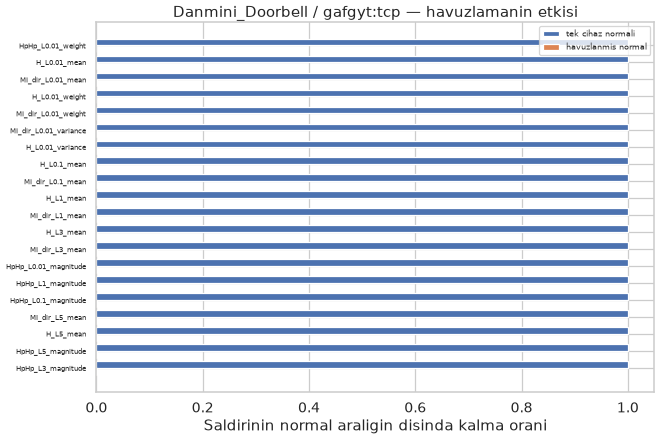

In [9]:
# ---- Which features? -----------------------------------------------
ODAK = "Danmini_Doorbell"
if ODAK in CIHAZLAR and "gafgyt:tcp" in SALDIRI[ODAK]:
    iyi = BOLUM[ODAK]["kalibrasyon"]; S = SALDIRI[ODAK]["gafgyt:tcp"]
    d_tek = disarida_oran(iyi, S)
    d_havuz = disarida_oran(havuz_iyi, S)
    onem = pd.DataFrame({"oznitelik": OZNITELIKLER,
                         "tek_cihaz": d_tek, "havuz": d_havuz,
                         "kayip": d_tek - d_havuz}).sort_values("kayip", ascending=False)
    onem.to_csv(f"{OUT}/tables/f3_tablo4_oznitelik_kaybi.csv", index=False)
    print(f"{ODAK} / gafgyt:tcp — 15 features losing the most discriminative power:\n")
    print(onem.head(15).to_string(index=False))

    ilk = onem.head(20)
    plt.figure(figsize=(12, 8))
    y = np.arange(len(ilk))
    plt.barh(y - 0.2, ilk.tek_cihaz, 0.4, label="tek cihaz normali", color="#4c72b0")
    plt.barh(y + 0.2, ilk.havuz,     0.4, label="havuzlanmis normal", color="#dd8452")
    plt.yticks(y, [o[:34] for o in ilk.oznitelik], fontsize=8)
    plt.gca().invert_yaxis(); plt.legend(fontsize=10)
    plt.xlabel("Saldirinin normal araligin disinda kalma orani")
    plt.title(f"{ODAK[:24]} / gafgyt:tcp — havuzlamanin etkisi")
    savefig("f3_fig05_oznitelik_kaybi")
else:
    print("Focus device or attack type not found.")

# Part C — Cold-start curve (RQ2)

**Question:** How many records of clean traffic does it take before a device newly joining the network is protected?

The calibration window is enlarged gradually: 250, 500, 1000, 2500, 5000, 10000, 25000
records, and the full set. The threshold slice and test slice are held fixed so results remain
comparable.

**Reverse hypothesis to test:** If Part B is right, more data widens the "normal" region.
Then beyond some point **more data may worsen detection**. This would be a finding that
contradicts the field's "more data is better" assumption.

Each point is run with two seeds — the noise floor is measured here as well.

In [10]:
def ae_kur(boyut, tohum):
    set_seed(tohum)
    inp = layers.Input(shape=(boyut,))
    x = layers.Dense(64, activation="relu")(inp)
    x = layers.Dense(32, activation="relu")(x)
    k = layers.Dense(KOD_BOYUT, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(k)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(boyut, activation="linear")(x)
    m = models.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="mse")
    return m

def egit(kal, tohum):
    mu = kal.mean(0); sd = kal.std(0) + 1e-8
    X = np.clip((kal - mu) / sd, -20, 20).astype("float32")
    nv = max(1, int(0.1 * len(X)))
    m = ae_kur(X.shape[1], tohum)
    m.fit(X[:-nv], X[:-nv], validation_data=(X[-nv:], X[-nv:]),
          epochs=EPOCHS, batch_size=min(BATCH, max(8, len(X)//10)), verbose=0,
          callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                             restore_best_weights=True)])
    return m, mu, sd

def hata(m, mu, sd, A):
    X = np.clip((A - mu) / sd, -20, 20).astype("float32")
    R = m.predict(X, batch_size=4096, verbose=0)
    return np.mean((X - R) ** 2, axis=1)

def skorla(iyi_h, sal_h, esik):
    tum = np.concatenate(list(sal_h.values()))
    zor = [sal_h[t] for t in ZOR_TURLER if t in sal_h]
    y = np.r_[np.zeros(len(iyi_h)), np.ones(len(tum))]
    s = np.r_[iyi_h, tum]
    r = {"TPR_genel": float((tum > esik).mean()),
         "FPR": float((iyi_h > esik).mean()),
         "ROC_AUC_genel": float(roc_auc_score(y, s))}
    if zor:
        Z = np.concatenate(zor)
        yz = np.r_[np.zeros(len(iyi_h)), np.ones(len(Z))]
        sz = np.r_[iyi_h, Z]
        r["TPR_zor"] = float((Z > esik).mean())
        r["ROC_AUC_zor"] = float(roc_auc_score(yz, sz))
    return r

In [11]:
if os.path.exists(CKPT):
    with open(CKPT, "rb") as f: D3 = pickle.load(f)
    print(f"Previous checkpoint: {len(D3['sogut'])} runs")
else:
    D3 = {"sogut": []}
    print("New run")

tamam = {(r["cihaz"], r["pencere"], r["tohum"]) for r in D3["sogut"]}
t0 = time.time()

for cihaz in CIHAZLAR:
    kal_tam = BOLUM[cihaz]["kalibrasyon"]
    esik_veri = BOLUM[cihaz]["esik"]
    iyi_test = BOLUM[cihaz]["test"]
    print(f"\n--- {cihaz[:40]}  (calibration pool {len(kal_tam):,}) ---")

    for pen in PENCERELER:
        n = len(kal_tam) if pen is None else min(pen, len(kal_tam))
        etiket = "tamami" if pen is None else str(pen)
        if pen is not None and pen > len(kal_tam):
            continue                      # this device does not have that much data
        for tohum in (SEED, SEED2):
            if (cihaz, etiket, tohum) in tamam: continue
            kal = kal_tam[:n]
            m, mu, sd = egit(kal, tohum)
            esik = float(np.quantile(hata(m, mu, sd, esik_veri), 1 - HEDEF_FPR))
            iyi_h = hata(m, mu, sd, iyi_test)
            sal_h = {t: hata(m, mu, sd, A) for t, A in SALDIRI[cihaz].items()}
            r = {"cihaz": cihaz, "pencere": etiket, "n_kalibrasyon": n,
                 "tohum": tohum, **skorla(iyi_h, sal_h, esik)}
            D3["sogut"].append(r)
            del m; tf.keras.backend.clear_session()
        son = [r for r in D3["sogut"] if r["cihaz"]==cihaz and r["pencere"]==etiket]
        if son:
            print(f"  n={n:>7,}  TPR_genel={np.mean([r['TPR_genel'] for r in son]):.4f}"
                  f"  TPR_zor={np.mean([r.get('TPR_zor',np.nan) for r in son]):.4f}"
                  f"  AUC_zor={np.mean([r.get('ROC_AUC_zor',np.nan) for r in son]):.4f}")
    with open(CKPT, "wb") as f: pickle.dump(D3, f)

print(f"\nTotal time: {(time.time()-t0)/60:.1f} minutes")
sog = pd.DataFrame(D3["sogut"])
sog.to_csv(f"{OUT}/tables/f3_tablo5_sogut_baslangic_ham.csv", index=False)

Yeni kosu

--- Danmini_Doorbell  (kalibrasyon havuzu 29,728) ---


W0000 00:00:1790678680.725035  234339 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790678680.807054  234339 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 94890 MB memory:  -> device: 0, name: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, pci bus id: 0000:02:00.0, compute capability: 12.0a
I0000 00:00:1790678682.500893  234567 service.cc:153] XLA service 0x7935ac0333d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790678682.500916  234567 service.cc:161]   StreamExecutor [0]: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1790678682.516543  234567 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var

  n=    250  TPR_genel=0.7994  TPR_zor=0.0010  AUC_zor=0.9756


I0000 00:00:1790678703.904080  234553 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_17823__.9
I0000 00:00:1790678703.910315  234553 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790678704.093603  247311 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_38', 16 bytes spill stores, 16 bytes spill loads

I0000 00:00:1790678704.191984  247306 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_38', 16 bytes spill stores, 16 bytes spill loads

I0000 00:00:1790678704.274789  234553 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a 

  n=    500  TPR_genel=1.0000  TPR_zor=1.0000  AUC_zor=0.9930


...

  n=  5,000  TPR_genel=0.7972  TPR_zor=0.0004  AUC_zor=0.9884


I0000 00:00:1790680115.392417  234553 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1754154__.9
I0000 00:00:1790680116.330917  234564 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1754154__.9
I0000 00:00:1790680126.612522  234564 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1767469__.9
I0000 00:00:1790680127.582544  234553 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1767469__.9


  n= 10,000  TPR_genel=0.7973  TPR_zor=0.0007  AUC_zor=0.9907


I0000 00:00:1790680137.909315  234566 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1780904__.9
I0000 00:00:1790680138.911900  234567 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1780904__.9
I0000 00:00:1790680138.918172  234567 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790680139.237766  234567 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1790680139.457343 1042188 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_24', 64 bytes spill stores,

  n= 11,716  TPR_genel=0.7973  TPR_zor=0.0007  AUC_zor=0.9862

Toplam sure: 24.8 dakika


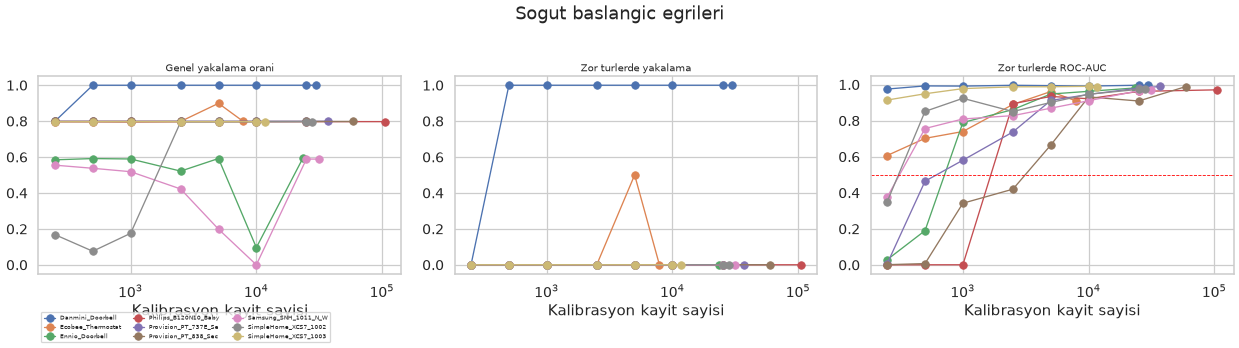

Gurultu tabani (ayni pencerede iki tohum arasi TPR farki):
  ortalama 0.0182  |  en buyuk 0.3957


In [12]:
# ---- Learning curves ---------------------------------------------------
sog = pd.DataFrame(D3["sogut"])
ort = (sog.groupby(["cihaz", "pencere", "n_kalibrasyon"])
          .agg(TPR_genel=("TPR_genel","mean"), TPR_zor=("TPR_zor","mean"),
               AUC_zor=("ROC_AUC_zor","mean"), FPR=("FPR","mean"),
               gurultu=("TPR_genel", lambda x: x.max()-x.min()))
          .reset_index().sort_values(["cihaz","n_kalibrasyon"]))
ort.to_csv(f"{OUT}/tables/f3_tablo6_sogut_ozet.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, met, bas in zip(axes,
                        ["TPR_genel", "TPR_zor", "AUC_zor"],
                        ["Genel yakalama orani", "Zor turlerde yakalama",
                         "Zor turlerde ROC-AUC"]):
    for c in CIHAZLAR:
        g = ort[ort.cihaz == c]
        ax.plot(g.n_kalibrasyon, g[met], marker="o", lw=1.6, label=c[:20])
    ax.set_xscale("log"); ax.set_xlabel("Kalibrasyon kayit sayisi")
    ax.set_title(bas, fontsize=12)
axes[2].axhline(0.5, color="red", ls="--", lw=1)
axes[0].legend(fontsize=7, bbox_to_anchor=(0, -0.18), loc="upper left", ncol=3)
plt.suptitle("Sogut baslangic egrileri", y=1.02)
plt.tight_layout(); savefig("f3_fig06_sogut_baslangic")

print("Noise floor (TPR difference between two seeds at the same window):")
print(f"  mean {ort.gurultu.mean():.4f}  |  max {ort.gurultu.max():.4f}")

In [13]:
# ---- Is more data always better? ------------------------------
satir = []
for c in CIHAZLAR:
    g = ort[ort.cihaz == c].sort_values("n_kalibrasyon")
    if len(g) < 3: continue
    for met in ["TPR_genel", "TPR_zor", "AUC_zor"]:
        v = g[met].to_numpy()
        if np.all(np.isnan(v)): continue
        en_iyi = int(np.nanargmax(v))
        satir.append({
            "cihaz": c, "metrik": met,
            "en_iyi_pencere": g.n_kalibrasyon.iloc[en_iyi],
            "en_iyi_deger": round(float(v[en_iyi]), 4),
            "tam_veri_degeri": round(float(v[-1]), 4),
            "fark": round(float(v[en_iyi] - v[-1]), 4),
            "tam_veri_en_iyi_mi": bool(en_iyi == len(v) - 1),
        })
tepe = pd.DataFrame(satir)
tepe.to_csv(f"{OUT}/tables/f3_tablo7_tepe_noktasi.csv", index=False)

for met in ["TPR_genel", "TPR_zor", "AUC_zor"]:
    alt = tepe[tepe.metrik == met]
    if alt.empty: continue
    oran = alt.tam_veri_en_iyi_mi.mean()
    print(f"\n{met}: share of devices where full data is best = "
          f"{oran:.2f}  ({int(alt.tam_veri_en_iyi_mi.sum())}/{len(alt)})")
    kotu = alt[~alt.tam_veri_en_iyi_mi].nlargest(4, "fark")
    if not kotu.empty:
        print("  Devices where full data falls BEHIND:")
        for _, r in kotu.iterrows():
            print(f"    {r.cihaz[:32]:<34} best n={r.en_iyi_pencere:>7,} "
                  f"({r.en_iyi_deger:.4f}) vs full ({r.tam_veri_degeri:.4f})  "
                  f"diff {r.fark:+.4f}")

print("\nINTERPRETATION: if the 'full data is best' share is low, the hypothesis that more calibration data")
print("widens the normal region and worsens detection is supported.")


TPR_genel: tam verinin en iyi oldugu cihaz orani = 0.33  (3/9)
  Tam verinin GERIDE kaldigi cihazlar:
    Ecobee_Thermostat                  en iyi n=  5,000 (0.8992) vs tam (0.7985)  fark +0.1007
    Danmini_Doorbell                   en iyi n=  2,500 (1.0000) vs tam (1.0000)  fark +0.0000
    Provision_PT_737E_Security_Camer   en iyi n= 25,000 (0.7995) vs tam (0.7995)  fark +0.0000
    Samsung_SNH_1011_N_Webcam          en iyi n= 25,000 (0.5890) vs tam (0.5889)  fark +0.0000

TPR_zor: tam verinin en iyi oldugu cihaz orani = 0.56  (5/9)
  Tam verinin GERIDE kaldigi cihazlar:
    Ecobee_Thermostat                  en iyi n=  5,000 (0.5004) vs tam (0.0009)  fark +0.4995
    Provision_PT_737E_Security_Camer   en iyi n= 25,000 (0.0009) vs tam (0.0007)  fark +0.0001
    Danmini_Doorbell                   en iyi n=  2,500 (1.0000) vs tam (1.0000)  fark +0.0000
    Samsung_SNH_1011_N_Webcam          en iyi n= 25,000 (0.0002) vs tam (0.0002)  fark +0.0000

AUC_zor: tam verinin en iyi oldugu 

In [14]:
# ---- Saturation point: how many records to reach 95% of the best? -------
satir = []
for c in CIHAZLAR:
    g = ort[ort.cihaz == c].sort_values("n_kalibrasyon")
    for met in ["TPR_genel", "AUC_zor"]:
        v = g[met].to_numpy()
        if np.all(np.isnan(v)): continue
        hedef = 0.95 * np.nanmax(v)
        ulasan = g.n_kalibrasyon.to_numpy()[np.where(v >= hedef)[0]]
        satir.append({"cihaz": c, "metrik": met,
                      "doygunluk_n": int(ulasan[0]) if len(ulasan) else None,
                      "en_iyi": round(float(np.nanmax(v)), 4)})
doy = pd.DataFrame(satir)
doy.to_csv(f"{OUT}/tables/f3_tablo8_doygunluk.csv", index=False)
print("Number of calibration records needed to reach 95% of best performance:\n")
print(doy.pivot(index="cihaz", columns="metrik", values="doygunluk_n").to_string())
print("\nN-BaIoT records are roughly one-second traffic summaries;")
print("these numbers can be read roughly as 'how many seconds of clean traffic suffice'.")

En iyi basarimin %95'ine ulasmak icin gereken kalibrasyon kayit sayisi:

metrik                                    AUC_zor  TPR_genel
cihaz                                                       
Danmini_Doorbell                              250        500
Ecobee_Thermostat                            5000       5000
Ennio_Doorbell                               5000        250
Philips_B120N10_Baby_Monitor                 5000        250
Provision_PT_737E_Security_Camera           10000        250
Provision_PT_838_Security_Camera            59108        250
Samsung_SNH_1011_N_Webcam                   25000      25000
SimpleHome_XCS7_1002_WHT_Security_Camera    10000       2500
SimpleHome_XCS7_1003_WHT_Security_Camera      500        250

N-BaIoT kayitlari yaklasik saniyelik trafik ozetleridir;
bu sayilar kabaca 'kac saniyelik temiz trafik yeterli' olarak okunabilir.


## Summary and packaging

In [15]:
ozet_json = {
    "bolum_A_tani": {
        t: {"TPR": round(float(dd.loc[t, "TPR@esik"]), 4),
            "ROC_AUC": round(float(dd.loc[t, "ROC_AUC"]), 4)}
        for t in dd.index
    },
    "bolum_B_normal_genisleme_medyan": {
        r.cihaz: round(float(r.ortalama_genisleme), 3) for _, r in gen.iterrows()
    },
    "bolum_C": {
        "gurultu_tabani_TPR": round(float(ort.gurultu.mean()), 4),
        "tam_veri_en_iyi_orani": {
            met: round(float(tepe[tepe.metrik == met].tam_veri_en_iyi_mi.mean()), 3)
            for met in tepe.metrik.unique()
        },
    },
}
with open(f"{OUT}/tables/f3_ozet.json", "w") as fh:
    json.dump(ozet_json, fh, indent=2, ensure_ascii=False)
print(json.dumps(ozet_json, indent=2, ensure_ascii=False))

import shutil
ars = shutil.make_archive(os.path.expanduser("~/work/IoT_Botnet/faz3_ciktilar"),
                          "zip", OUT)
print("\nArchive:", ars, f"({os.path.getsize(ars)/1e6:.1f} MB)")

{
  "bolum_A_tani": {
    "gafgyt:udp": {
      "TPR": 0.1115,
      "ROC_AUC": 0.9714
    },
    "gafgyt:tcp": {
      "TPR": 0.1119,
      "ROC_AUC": 0.9714
    },
    "gafgyt:scan": {
      "TPR": 0.9998,
      "ROC_AUC": 0.9999
    },
    "mirai:scan": {
      "TPR": 0.9994,
      "ROC_AUC": 1.0
    },
    "mirai:syn": {
      "TPR": 0.9999,
      "ROC_AUC": 1.0
    },
    "gafgyt:junk": {
      "TPR": 0.9999,
      "ROC_AUC": 1.0
    },
    "gafgyt:combo": {
      "TPR": 0.9999,
      "ROC_AUC": 1.0
    },
    "mirai:udp": {
      "TPR": 0.9998,
      "ROC_AUC": 1.0
    },
    "mirai:udpplain": {
      "TPR": 1.0,
      "ROC_AUC": 1.0
    },
    "mirai:ack": {
      "TPR": 0.9999,
      "ROC_AUC": 1.0
    }
  },
  "bolum_B_normal_genisleme_medyan": {
    "SimpleHome_XCS7_1003_WHT_Security_Camera": 30.252,
    "Danmini_Doorbell": 10.456,
    "Ennio_Doorbell": 2.91,
    "Philips_B120N10_Baby_Monitor": 2.853,
    "SimpleHome_XCS7_1002_WHT_Security_Camera": 1.318,
    "Provision_PT_73

---

## Post-run checklist

1. **What is the ROC-AUC of the hard types?** Around 0.5 means invisibility, high means a threshold problem.
   This is the single number that determines the direction of the study.
2. **By how many times does pooling widen the normal region?** Is it higher for Danmini than for the others?
3. **In cold start, is the full data always the best?** If not, the reverse hypothesis is supported.
4. **Where is the saturation point?** The practical recommendation will come from this number.
5. **Is the noise floor small?** If large, fluctuations in the curves are meaningless.